**Student ID: MS26910222** — IT5092 Lab Sheet 9: Information-Theoretic Analysis of Neural Responses

### Exercise 1 — Entropy of Neural Responses

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from entropy_utils import compute_entropy,normalize_distribution

In [2]:
# Simulate Spike Count Distribution

spike_counts = np.array([0, 1, 2])
probabilities = np.array([0.5, 0.25, 0.25])

H = compute_entropy(probabilities)

print("Entropy H(R):", H, "bits")

Entropy H(R): 1.5 bits


### Task

Change distribution to:

[0.95, 0.05]
Observe entropy change.

In [3]:
# Task: skewed distribution [0.95, 0.05]
original = np.array([0.5, 0.25, 0.25])
skewed   = np.array([0.95, 0.05])

H_original = compute_entropy(original)
H_skewed   = compute_entropy(skewed)

print(f"Original distribution {original.tolist()} -> H = {H_original:.4f} bits")
print(f"Skewed distribution   {skewed.tolist()} -> H = {H_skewed:.4f} bits")
print(f"Max entropy for 2 outcomes = log2(2) = 1 bit; skewed reaches {H_skewed:.1%} of it")

# normalize_distribution check (raw counts -> probabilities)
print("normalize_distribution([95, 5]) =", normalize_distribution([95, 5]))

Original distribution [0.5, 0.25, 0.25] -> H = 1.5000 bits
Skewed distribution   [0.95, 0.05] -> H = 0.2864 bits
Max entropy for 2 outcomes = log2(2) = 1 bit; skewed reaches 28.6% of it
normalize_distribution([95, 5]) = [0.95 0.05]


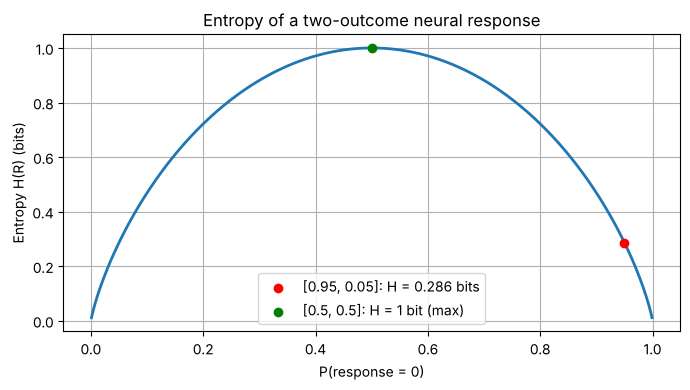

In [4]:
# Binary entropy curve: how uncertainty depends on how skewed P(spike) is
p = np.linspace(0.001, 0.999, 500)
H_curve = [compute_entropy([pi, 1 - pi]) for pi in p]

plt.figure(figsize=(7, 4))
plt.plot(p, H_curve, lw=2)
plt.scatter([0.95], [H_skewed], color='red', zorder=3, label=f'[0.95, 0.05]: H = {H_skewed:.3f} bits')
plt.scatter([0.5], [1.0], color='green', zorder=3, label='[0.5, 0.5]: H = 1 bit (max)')
plt.xlabel('P(response = 0)'); plt.ylabel('Entropy H(R) (bits)')
plt.title('Entropy of a two-outcome neural response')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig('fig_ex1_entropy_curve.png', dpi=150)
plt.show()

**Q1 answer:** Entropy falls from **1.5 bits** (original [0.5, 0.25, 0.25]) to **0.286 bits** for [0.95, 0.05]. The skewed distribution carries **less uncertainty**: the neuron almost always gives the same response, so it is highly predictable. Entropy is highest when outcomes are equally likely (1 bit for two outcomes).

### Exercise 2 — Mutual Information

In [5]:
# Simulate Stimulus-Response Mapping
np.random.seed(0)

stimulus = np.random.choice([0, 1], size=1000)

response = stimulus + np.random.normal(0, 0.5, size=1000)
response = (response > 0.5).astype(int)

In [6]:
# Compute MI
from mutual_information import compute_mutual_information

I = compute_mutual_information(stimulus, response)
print("Mutual Information:", I, "bits")

Mutual Information: 0.4263533917403184 bits


### Task
Increase noise.
Observe MI change.
Explain why.

In [7]:
# Task: increase noise SD from 0.5 to 2.0 (same seed so only the noise changes)
def simulate(noise_std, n=1000, seed=0):
    np.random.seed(seed)
    s = np.random.choice([0, 1], size=n)
    r = s + np.random.normal(0, noise_std, size=n)
    r = (r > 0.5).astype(int)
    return s, r

for noise_std in [0.5, 2.0]:
    s, r = simulate(noise_std)
    I_val = compute_mutual_information(s, r)
    accuracy = np.mean(s == r)
    print(f"noise SD = {noise_std}:  I(S;R) = {I_val:.4f} bits   "
          f"H(S) = {compute_entropy(np.bincount(s) / len(s)):.4f} bits   response accuracy = {accuracy:.1%}")

noise SD = 0.5:  I(S;R) = 0.4264 bits   H(S) = 1.0000 bits   response accuracy = 86.4%
noise SD = 2.0:  I(S;R) = 0.0517 bits   H(S) = 1.0000 bits   response accuracy = 63.3%


noise SD = 0.0   mean I(S;R) = 0.9994 bits
noise SD = 0.1   mean I(S;R) = 0.9994 bits
noise SD = 0.25  mean I(S;R) = 0.8420 bits
noise SD = 0.5   mean I(S;R) = 0.3682 bits
noise SD = 0.75  mean I(S;R) = 0.1830 bits
noise SD = 1.0   mean I(S;R) = 0.1081 bits
noise SD = 1.5   mean I(S;R) = 0.0478 bits
noise SD = 2.0   mean I(S;R) = 0.0273 bits
noise SD = 3.0   mean I(S;R) = 0.0118 bits


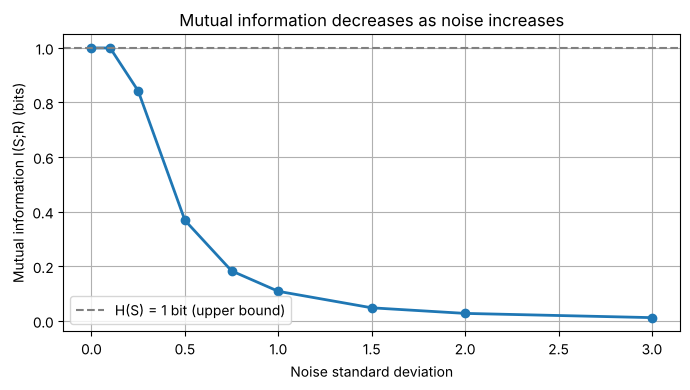

In [8]:
# MI as a function of noise (averaged over 20 seeds)
noise_levels = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
mi_mean = [np.mean([compute_mutual_information(*simulate(ns, seed=k)) for k in range(20)])
           for ns in noise_levels]
for ns, m in zip(noise_levels, mi_mean):
    print(f"noise SD = {ns:<5} mean I(S;R) = {m:.4f} bits")

plt.figure(figsize=(7, 4))
plt.plot(noise_levels, mi_mean, 'o-', lw=2)
plt.axhline(1.0, color='gray', ls='--', label='H(S) = 1 bit (upper bound)')
plt.xlabel('Noise standard deviation'); plt.ylabel('Mutual information I(S;R) (bits)')
plt.title('Mutual information decreases as noise increases')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig('fig_ex2_mi_vs_noise.png', dpi=150)
plt.show()

**Q2 answer:** With noise SD = 0.5, I(S;R) ≈ **0.43 bits**; with SD = 2.0 it drops to ≈ **0.05 bits**, close to zero. Noise makes the response depend less on the stimulus: the same stimulus can give different responses and different stimuli can give the same response. The overlap between the two response distributions grows, so observing R reduces our uncertainty about S much less (H(S|R) rises towards H(S) = 1 bit).

### Exercise 3 — Spike Timing Information

In [9]:
#Create two spike trains:
train_A = [10, 20, 30]
train_B = [70, 80, 90]

In [10]:
from spike_train_analysis import compute_spike_train_entropy

### Compare entropy using:

Bin size = 100 ms
Bin size = 10 ms

Explain difference.

In [11]:
from spike_train_analysis import bin_spike_train

duration = 100  # ms
trains = [train_A, train_B]

for bin_size in [100, 10]:
    print(f"Bin size = {bin_size} ms")
    print("  train_A binned:", bin_spike_train(train_A, duration, bin_size))
    print("  train_B binned:", bin_spike_train(train_B, duration, bin_size))
    H_bin = compute_spike_train_entropy(trains, duration, bin_size)
    print(f"  Spike train entropy = {H_bin:.4f} bits\n")

Bin size = 100 ms
  train_A binned: [3]
  train_B binned: [3]
  Spike train entropy = 0.0000 bits

Bin size = 10 ms
  train_A binned: [0 1 1 1 0 0 0 0 0 0]
  train_B binned: [0 0 0 0 0 0 0 1 1 1]
  Spike train entropy = 1.0000 bits



bin = 100 ms  ->  H = 2.984 bits
bin =  50 ms  ->  H = 4.804 bits
bin =  25 ms  ->  H = 6.907 bits
bin =  10 ms  ->  H = 8.474 bits
bin =   5 ms  ->  H = 8.725 bits
bin =   2 ms  ->  H = 8.857 bits
bin =   1 ms  ->  H = 8.893 bits
(upper limit set by number of trials: log2(500) = 8.97 bits)


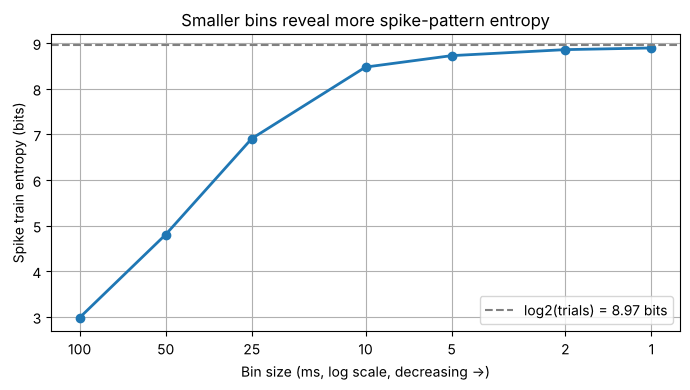

In [12]:
# Extra: entropy vs bin size for many random (Poisson, 40 Hz) spike trains
rng = np.random.default_rng(1)
n_trials, rate_hz = 500, 40
poisson_trains = []
for _ in range(n_trials):
    n_spk = rng.poisson(rate_hz * duration / 1000)
    poisson_trains.append(np.sort(rng.uniform(0, duration, n_spk)))

bin_sizes = [100, 50, 25, 10, 5, 2, 1]
H_bins = [compute_spike_train_entropy(poisson_trains, duration, b) for b in bin_sizes]
for b, h in zip(bin_sizes, H_bins):
    print(f"bin = {b:>3} ms  ->  H = {h:.3f} bits")
print(f"(upper limit set by number of trials: log2({n_trials}) = {np.log2(n_trials):.2f} bits)")

plt.figure(figsize=(7, 4))
plt.semilogx(bin_sizes, H_bins, 'o-', lw=2)
plt.axhline(np.log2(n_trials), color='gray', ls='--', label=f'log2(trials) = {np.log2(n_trials):.2f} bits')
plt.gca().invert_xaxis()
plt.xticks(bin_sizes, [str(b) for b in bin_sizes])
plt.minorticks_off()
plt.xlabel('Bin size (ms, log scale, decreasing →)'); plt.ylabel('Spike train entropy (bits)')
plt.title('Smaller bins reveal more spike-pattern entropy')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig('fig_ex3_entropy_vs_bin.png', dpi=150)
plt.show()

**Q3 answer:** With 100 ms bins both trains become the same pattern [3] (three spikes), so entropy = **0 bits** and they cannot be told apart. With 10 ms bins the timing is preserved ([0 1 1 1 0 0 0 0 0 0] vs [0 0 0 0 0 0 0 1 1 1]), the two patterns differ, and entropy = **1 bit**. Smaller bins capture spike timing and increase entropy; very large bins reduce the code to a spike count, so any information carried by timing is lost.

### Exercise 4 — Coding Efficiency

In [13]:
from coding_efficiency import compare_distributions

compare_distributions()

Distribution  Probabilities              Entropy (bits)  Efficiency
-------------------------------------------------------------------
Uniform       [0.25, 0.25, 0.25, 0.25]           2.0000     100.0%
Skewed        [0.7, 0.1, 0.1, 0.1]               1.3568      67.8%

Maximum entropy for 4 states = log2(4) = 2.0 bits
More efficient distribution: Uniform (+0.6432 bits per symbol)


(2.0, 1.3567796494470397)

##### Which distribution is more efficient?
##### Why does uniform maximize entropy?

**Q4 answer:** The **uniform** distribution is more efficient: H = **2.0 bits** (the maximum, log2 4) vs **1.357 bits** for the skewed one (67.8% efficiency). Uniform maximizes entropy because no response level is more predictable than any other, so every response carries the most surprise. A neuron that uses all its firing-rate levels equally often transmits the most information per response for its limited range (cf. histogram equalization / efficient coding, Laughlin 1981).

In [14]:
# Supporting demo for critical questions 1 & 4:
# a neuron that fires randomly (independent of the stimulus) vs one that follows the stimulus
np.random.seed(0)
stim = np.random.choice([0, 1], size=5000)

random_neuron = np.random.choice([0, 1, 2, 3], size=5000)                 # high entropy, ignores stimulus
coding_neuron = stim * 2 + np.random.choice([0, 1], size=5000, p=[0.9, 0.1])  # depends on stimulus
high_rate_neuron = np.random.poisson(50, size=5000)                      # high rate, ignores stimulus

for name, r in [("Random neuron", random_neuron),
                ("Stimulus-coding neuron", coding_neuron),
                ("High-rate (50 spikes) random neuron", high_rate_neuron)]:
    H_r = compute_entropy(np.unique(r, return_counts=True)[1] / len(r))
    I_sr = compute_mutual_information(stim, r)
    print(f"{name:<38} mean count = {r.mean():6.2f}   H(R) = {H_r:.3f} bits   I(S;R) = {I_sr:.4f} bits")

Random neuron                          mean count =   1.47   H(R) = 1.998 bits   I(S;R) = 0.0002 bits
Stimulus-coding neuron                 mean count =   1.12   H(R) = 1.462 bits   I(S;R) = 0.9998 bits
High-rate (50 spikes) random neuron    mean count =  49.91   H(R) = 4.884 bits   I(S;R) = 0.0062 bits


### Critical Thinking Questions

**1. Can a neuron have high entropy but low mutual information?**
Yes. Entropy only measures how variable the response is; MI measures how much of that variability is *about the stimulus*. Since I(S;R) = H(R) − H(R|S), a neuron whose variability is pure noise has high H(R) but also high H(R|S), so MI ≈ 0. In the demo above the random neuron has H(R) ≈ 2 bits but I(S;R) ≈ 0.

**2. Why does noise reduce mutual information?**
Noise adds response variability that is unrelated to the stimulus. It increases the noise entropy H(R|S) and makes the response distributions for different stimuli overlap, so a response no longer identifies the stimulus reliably. In Exercise 2, MI fell from ≈0.43 bits (SD 0.5) to ≈0.05 bits (SD 2.0).

**3. How does bin size affect spike train entropy?**
Smaller bins keep more temporal detail, so more distinct spike patterns are possible and entropy rises (0 → 1 bit for train A vs B when going from 100 ms to 10 ms bins). Large bins collapse patterns into spike counts and timing information is lost. Very small bins, however, need much more data to estimate entropy reliably, and below the precision of real spike timing they mainly add noise entropy.

**4. Does a higher firing rate always imply higher information transmission?**
No. Information depends on how reliably the firing changes with the stimulus, not on the rate itself. A neuron firing at a constant high rate, or a high rate unrelated to the stimulus, transmits ≈0 bits (see demo: 50 spikes, I ≈ 0). Higher rates can carry more information only if they vary with the stimulus; they also cost more energy, and saturating near the maximum rate reduces entropy again. Sparse, low-rate codes can be highly informative and energy efficient.